In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (classification_report, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve)


In [63]:
df = pd.read_csv('../data/kenya_synthetic_loans.csv')
print(df.shape)
print(df.columns.tolist())
display(pd.concat([df.head(), df.tail()]))

(5000, 18)
['loan_id', 'borrower_id', 'age', 'county', 'employment_type', 'monthly_income_kes', 'mpesa_avg_monthly_inflow_kes', 'mpesa_account_age_months', 'airtime_spend_monthly_kes', 'prior_loans', 'prior_defaults', 'active_loans_elsewhere', 'loan_amount_kes', 'term_days', 'fee_pct', 'channel', 'loan_to_income', 'defaulted_90dpd']


,loan_id,borrower_id,age,county,employment_type,monthly_income_kes,mpesa_avg_monthly_inflow_kes,mpesa_account_age_months,airtime_spend_monthly_kes,prior_loans,prior_defaults,active_loans_elsewhere,loan_amount_kes,term_days,fee_pct,channel,loan_to_income,defaulted_90dpd
0,L02765,B01921,41,Eldoret,Salaried,33300,22700,18,2300,0,0,0,15000,30,10.3,Mobile App,0.450,0
1,L04768,B03336,30,Mombasa,Salaried,116600,138700,57,3160,0,0,3,8100,21,6.8,Mobile App,0.069,0
2,L03815,B02652,44,Mombasa,Salaried,47300,64400,34,2890,0,0,0,18000,90,19.6,Mobile App,0.381,0
3,L03500,B02428,32,Machakos,Casual,16000,19600,49,680,0,0,1,5000,30,11.4,Mobile App,0.312,0
4,L02736,B01898,28,Nairobi,Self-employed,39600,50200,47,1830,0,0,1,10700,21,7.1,Mobile App,0.270,0
4995,L02896,B02007,22,Eldoret,Self-employed,42000,27200,8,1760,0,0,0,2600,60,14.4,Mobile App,0.062,0
4996,L02764,B01920,22,Nairobi,Self-employed,75600,75100,59,2120,0,0,2,14700,90,17.9,Bank digital,0.194,0
4997,L00906,B00629,18,Mombasa,Casual,8900,11900,41,480,2,1,3,4200,14,8.0,Mobile App,0.472,0
4998,L03981,B02773,31,Nakuru,Salaried,61900,48500,78,3460,0,0,1,9100,14,12.3,Mobile App,0.147,0
4999,L00236,B00167,35,Nairobi,Casual,17900,17700,46,780,0,0,4,13700,7,13.0,Mobile App,0.765,1


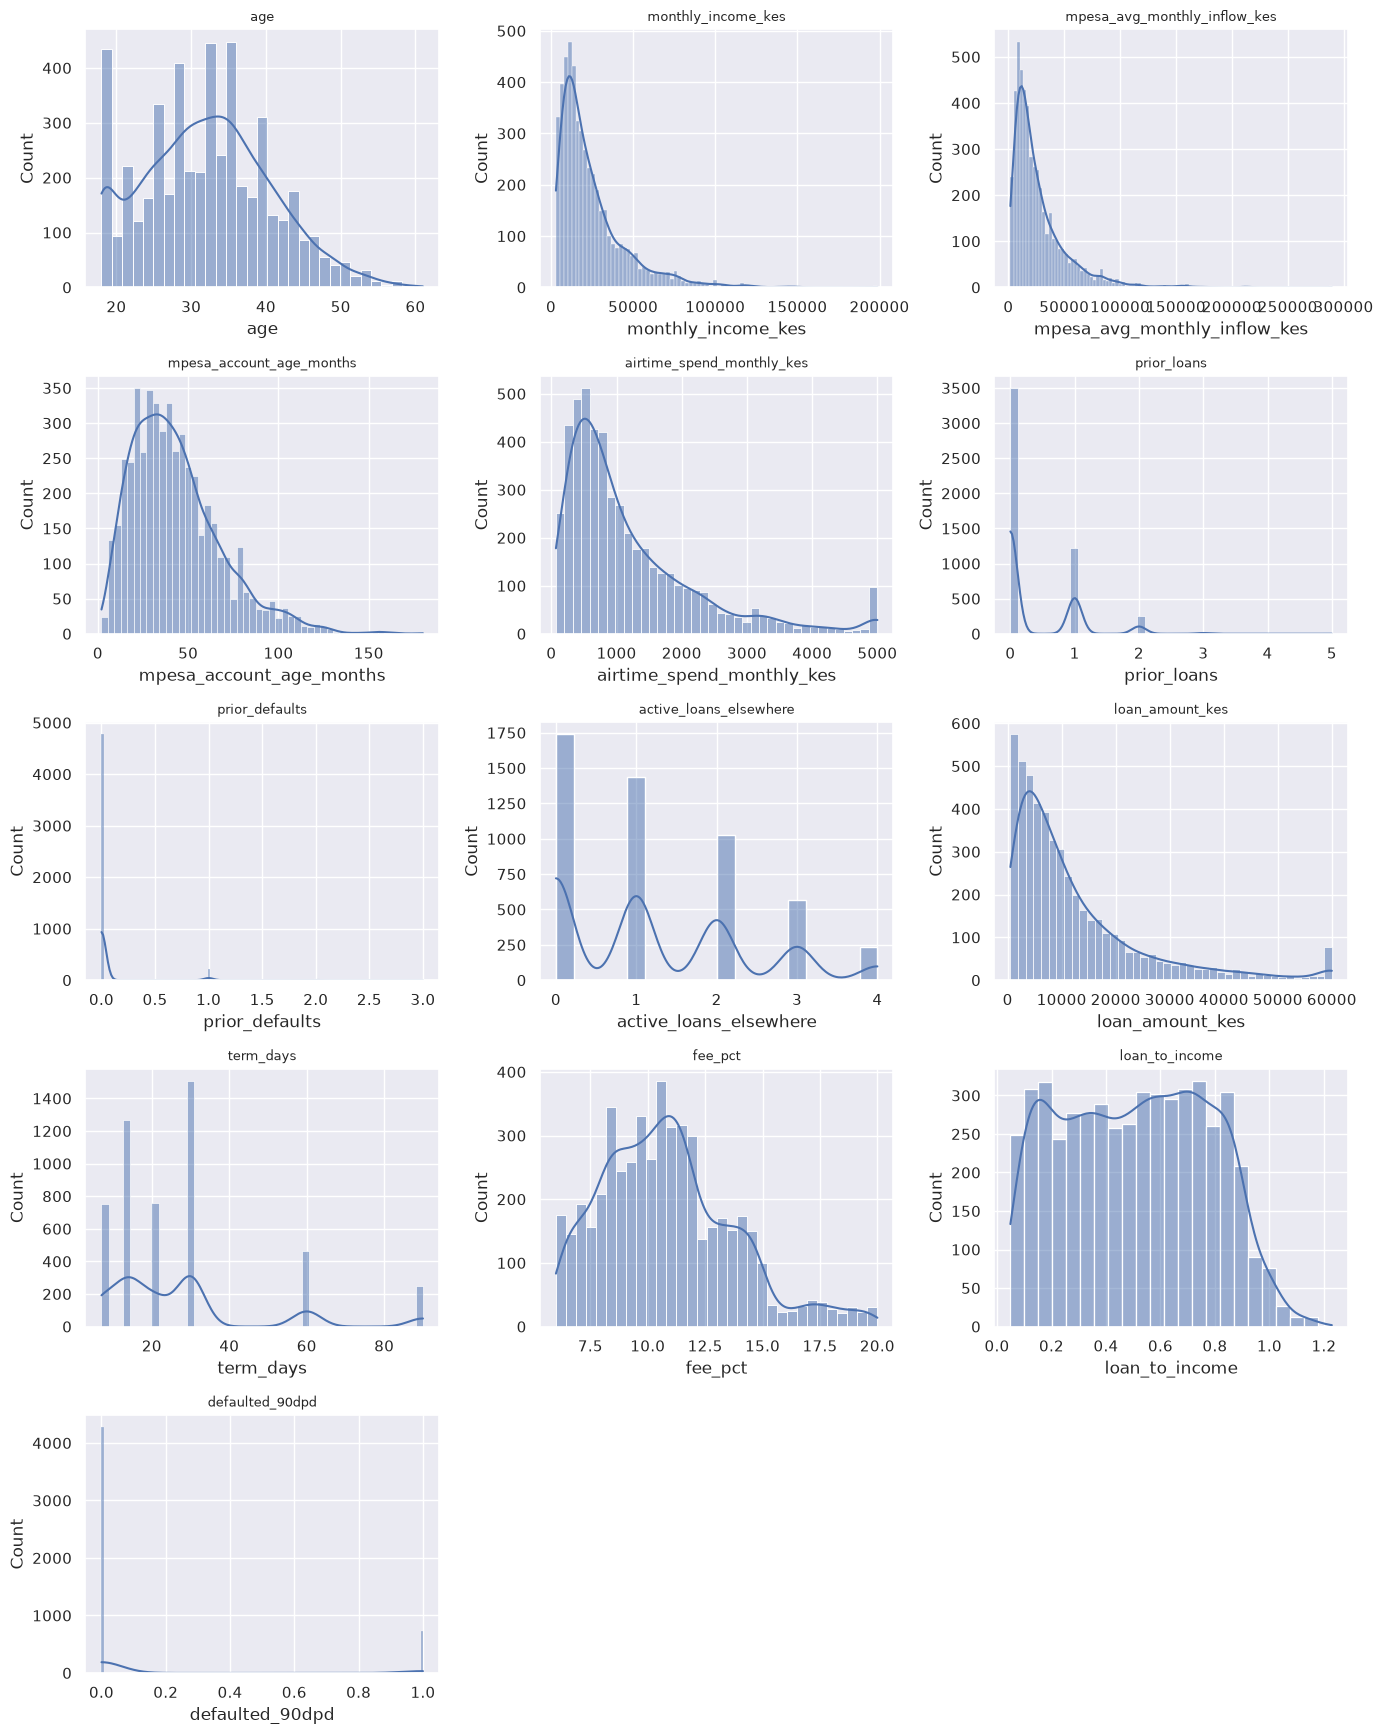

In [64]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

n = len(numeric_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
axes = axes.flat

for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col, fontsize=9)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [65]:
for col in ["county", "employment_type", "channel"]:
    df[col] = pd.Categorical(df[col]).codes

In [ ]:
# --- keep borrower_id around for grouping ---
data = df.copy()
groups = data["borrower_id"]
y = data["defaulted_90dpd"]
X = data.drop(columns=["loan_id", "borrower_id", "defaulted_90dpd"])


In [ ]:
# --- grouped split so the same borrower is never in both sets ---
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[tr], X.iloc[te]
y_train, y_test = y.iloc[tr], y.iloc[te]

print(f"train={len(X_train)}  test={len(X_test)}  "
      f"default rate train={y_train.mean():.3f} test={y_test.mean():.3f}")


In [ ]:
# --- fit with class balancing + leaf-size floor ---
tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42,
)
tree.fit(X_train, y_train)

# --- evaluate the right way ---
y_pred  = tree.predict(X_test)
y_proba = tree.predict_proba(X_test)[:, 1]

print("Accuracy:", tree.score(X_test, y_test))
print("ROC-AUC :", roc_auc_score(y_test, y_proba))
print("PR-AUC  :", average_precision_score(y_test, y_proba))
print()
print(classification_report(y_test, y_pred, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))


In [ ]:
# --- grouped cross-validation ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(tree, X, y, cv=cv, groups=groups, scoring="roc_auc")
print(f"\nGrouped CV ROC-AUC: {scores.mean():.3f} ± {scores.std():.3f}")

# --- readable tree ---
print(export_text(tree, feature_names=list(X.columns), max_depth=3))

# --- picture ---
plt.figure(figsize=(20, 8))
plot_tree(tree, feature_names=X.columns,
          class_names=["no default", "default"],
          filled=True, rounded=True, fontsize=7, max_depth=3)
plt.title("Decision tree (top 3 levels)")
plt.show()


In [ ]:
# --- tune the classification threshold for target recall ---
prec, rec, thr = precision_recall_curve(y_test, y_proba)
target_recall = 0.60
valid = np.flatnonzero(rec[:-1] >= target_recall)
if len(valid) == 0:
    raise ValueError(f"No threshold reaches recall >= {target_recall:.2f}")
idx = valid[-1]
threshold = thr[idx]
print(f"threshold={threshold:.2f}  precision={prec[idx]:.2f}  recall={rec[idx]:.2f}")
y_pred_tuned = (y_proba >= threshold).astype(int)
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_tuned))


In [ ]:
# --- compare one-hot county encoding with integer encoding ---
raw_data = pd.read_csv('../data/kenya_synthetic_loans.csv')
categorical_cols = ["county", "employment_type", "channel"]
onehot_data = pd.get_dummies(
    raw_data.drop(columns=["loan_id", "borrower_id", "defaulted_90dpd"]),
    columns=categorical_cols,
    dtype=float,
)
y_onehot = raw_data["defaulted_90dpd"]
X_onehot_train, X_onehot_test = onehot_data.iloc[tr], onehot_data.iloc[te]
y_onehot_train, y_onehot_test = y_onehot.iloc[tr], y_onehot.iloc[te]

tree_onehot = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42,
)
tree_onehot.fit(X_onehot_train, y_onehot_train)
onehot_proba = tree_onehot.predict_proba(X_onehot_test)[:, 1]
onehot_pred = tree_onehot.predict(X_onehot_test)
print("Integer-encoded PR-AUC:", round(average_precision_score(y_test, y_proba), 3))
print("One-hot PR-AUC         :", round(average_precision_score(y_onehot_test, onehot_proba), 3))
print("One-hot ROC-AUC        :", round(roc_auc_score(y_onehot_test, onehot_proba), 3))
print("\nOne-hot tree (top 3 levels):")
print(export_text(tree_onehot, feature_names=list(X_onehot_train.columns), max_depth=3))
